# What Drives Student Placement Success? A Data-Driven Investigation into Career Readiness

### An End-to-End Exploratory Data Analysis of the Student Career Success Dataset

---

## Problem Statement

Universities and career-services teams want to help every student walk out with a job offer in hand, but it's rarely clear which levers actually move the needle. Is it grades? Coding ability? Internships? Soft skills? Certifications?

This notebook investigates the following **central research question**:

> **What combination of academic, technical, and soft-skill factors most strongly predicts (a) whether a student gets placed in a job, and (b) how much they get paid — and can we build a practical, data-driven "Placement Readiness" scoring tool that students and career counselors can use to identify gaps and take action before graduation?**

To answer this, we break the problem into concrete, answerable sub-questions:

1. **Placement Landscape** — What share of students get placed, and how does that vary by major, gender, university year, and placement mode?
2. **Academic Factors** — Does CGPA / attendance / study hours actually correlate with getting placed and with salary — or is this a myth?
3. **Technical Factors** — How much do programming skill, projects, certifications, hackathons, GitHub presence, and internships matter?
4. **Soft Skills & Employability** — Do communication, teamwork, problem-solving, and English proficiency meaningfully affect outcomes?
5. **The Interview Bottleneck** — How well does interview score translate into placement and company tier?
6. **Salary Drivers** — Among placed students, what factors push starting salary up (company tier, major, career field, skills)?
7. **Composite Employability Score** — How well does the dataset's own `Employability_Score` explain placement/salary, and can we build an improved, transparent version?
8. **Predictive Solution** — Can we build a simple, explainable model that flags at-risk (likely-unplaced) students early, so counselors can intervene?

We will clean the data, explore it visually from multiple angles, quantify relationships statistically, build a practical predictive tool, and close with concrete, actionable recommendations for students, universities, and recruiters.


## 1. Setup & Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve)

# ---- Visual style ----
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 13

RANDOM_STATE = 42
pd.set_option('display.max_columns', 40)


## 2. Load the Data & First Look

In [2]:
df = pd.read_csv('student_career_success_dataset.csv')
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Shape: 50,000 rows x 29 columns


,Student_ID,Age,Gender,University_Year,Major,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Academic_Performance,Programming_Skill,Projects_Completed,Certifications,Hackathons,GitHub_Profile,Internships,Leadership_Experience,LinkedIn_Profile,Resume_Score,Communication_Skills,Teamwork,Problem_Solving,English_Proficiency,Interview_Score,Employability_Score,Placement_Status,Company_Tier,Career_Field,Placement_Mode,Starting_Salary_USD
0,ST000001,22,Male,Sophomore,Computer Science,86,21,3.28,Good,9,10,1,6,Yes,5,No,No,100,9,7,8,Advanced,72,231.70,Placed,Tier 1,Backend Developer,Campus Placement,72082
1,ST000002,20,Female,Freshman,Computer Science,64,18,2.53,Poor,6,6,0,5,Yes,2,No,Yes,80,5,6,5,Basic,59,157.45,Not Placed,No Company,Not Placed,Not Applicable,0
2,ST000003,23,Male,Senior,Information Technology,75,19,2.83,Average,8,9,0,5,Yes,3,Yes,No,100,7,8,7,Advanced,76,203.45,Placed,Tier 1,IT Support Engineer,Campus Placement,94898
3,ST000004,23,Female,Senior,Information Technology,80,19,2.80,Average,5,6,3,3,No,2,No,Yes,85,6,6,6,Intermediate,67,171.50,Not Placed,No Company,Not Placed,Not Applicable,0
4,ST000005,23,Female,Senior,Software Engineering,73,19,2.93,Average,9,10,1,2,Yes,3,Yes,Yes,100,10,8,9,Advanced,82,225.45,Placed,Tier 1,Software Engineer,Internship Conversion,85256


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             50000 non-null  str    
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  str    
 3   University_Year        50000 non-null  str    
 4   Major                  50000 non-null  str    
 5   Attendance_Percentage  50000 non-null  int64  
 6   Study_Hours_Per_Week   50000 non-null  int64  
 7   CGPA                   50000 non-null  float64
 8   Academic_Performance   50000 non-null  str    
 9   Programming_Skill      50000 non-null  int64  
 10  Projects_Completed     50000 non-null  int64  
 11  Certifications         50000 non-null  int64  
 12  Hackathons             50000 non-null  int64  
 13  GitHub_Profile         50000 non-null  str    
 14  Internships            50000 non-null  int64  
 15  Leadership_Ex

In [4]:
df.describe(include='number').T


,count,mean,std,min,25%,50%,75%,max
Age,50000.0,21.262900,2.041163,18.0,20.00,21.00,22.00,30.00
Attendance_Percentage,50000.0,81.409640,9.709519,50.0,75.00,82.00,88.00,100.00
Study_Hours_Per_Week,50000.0,21.528160,6.974810,5.0,17.00,21.00,26.00,45.00
CGPA,50000.0,3.106043,0.290351,2.0,2.91,3.11,3.31,4.00
Programming_Skill,50000.0,7.137160,1.507194,1.0,6.00,7.00,8.00,10.00
Projects_Completed,50000.0,8.620560,2.505408,0.0,7.00,9.00,10.00,15.00
Certifications,50000.0,1.715660,1.368301,0.0,1.00,2.00,3.00,8.00
Hackathons,50000.0,3.093940,1.660774,0.0,2.00,3.00,4.00,10.00
Internships,50000.0,4.048880,1.005719,0.0,3.00,4.00,5.00,5.00
Resume_Score,50000.0,96.045740,7.331565,44.0,95.00,100.00,100.00,100.00


In [5]:
df.describe(include='object').T


,count,unique,top,freq
Student_ID,50000,50000,ST000001,1
Gender,50000,3,Male,24533
University_Year,50000,4,Junior,14870
Major,50000,8,Computer Science,12407
Academic_Performance,50000,4,Average,28890
GitHub_Profile,50000,2,Yes,40680
Leadership_Experience,50000,2,No,30403
LinkedIn_Profile,50000,2,Yes,35917
English_Proficiency,50000,3,Advanced,39640
Placement_Status,50000,2,Placed,39040


## 3. Data Cleaning

We systematically check for: missing values, duplicate records, inconsistent categorical labels, invalid ranges (e.g. percentages > 100, negative values), and logical inconsistencies (e.g. a "Not Placed" student having a salary > 0). We then engineer a couple of helper features used throughout the analysis.


In [6]:
# 3.1 Missing values
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "None found — dataset is complete.")


Missing values per column:
None found — dataset is complete.


In [7]:
# 3.2 Duplicate rows / duplicate IDs
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated Student_IDs:", df['Student_ID'].duplicated().sum())


Fully duplicated rows: 0
Duplicated Student_IDs: 0


In [8]:
# 3.3 Range / sanity checks on numeric fields
checks = {
    'Attendance_Percentage': (0, 100),
    'CGPA': (0, 4.0),
    'Programming_Skill': (0, 10),
    'Resume_Score': (0, 100),
    'Communication_Skills': (0, 10),
    'Teamwork': (0, 10),
    'Problem_Solving': (0, 10),
    'Interview_Score': (0, 100),
    'Age': (15, 60),
}
for col, (lo, hi) in checks.items():
    bad = df[(df[col] < lo) | (df[col] > hi)]
    print(f"{col:25s} out-of-range rows: {len(bad)}")


Attendance_Percentage     out-of-range rows: 0
CGPA                      out-of-range rows: 0
Programming_Skill         out-of-range rows: 0
Resume_Score              out-of-range rows: 0
Communication_Skills      out-of-range rows: 0
Teamwork                  out-of-range rows: 0
Problem_Solving           out-of-range rows: 0
Interview_Score           out-of-range rows: 0
Age                       out-of-range rows: 0


In [9]:
# 3.4 Logical consistency: Not Placed students should have Starting_Salary_USD == 0
inconsistent = df[(df['Placement_Status'] == 'Not Placed') & (df['Starting_Salary_USD'] > 0)]
print("Inconsistent 'Not Placed but paid' rows:", len(inconsistent))

placed_zero = df[(df['Placement_Status'] == 'Placed') & (df['Starting_Salary_USD'] <= 0)]
print("Inconsistent 'Placed but zero salary' rows:", len(placed_zero))


Inconsistent 'Not Placed but paid' rows: 0
Inconsistent 'Placed but zero salary' rows: 0


In [10]:
# 3.5 Standardize text categories (strip whitespace, consistent casing) — defensive cleaning
cat_cols = df.select_dtypes(include='object').columns.tolist()
for c in cat_cols:
    df[c] = df[c].astype(str).str.strip()

print("Categorical columns cleaned:", cat_cols)


Categorical columns cleaned: ['Student_ID', 'Gender', 'University_Year', 'Major', 'Academic_Performance', 'GitHub_Profile', 'Leadership_Experience', 'LinkedIn_Profile', 'English_Proficiency', 'Placement_Status', 'Company_Tier', 'Career_Field', 'Placement_Mode']


In [11]:
# 3.6 Feature engineering for the analysis
# Binary flags to numeric
for col in ['GitHub_Profile', 'LinkedIn_Profile', 'Leadership_Experience']:
    df[col + '_Flag'] = df[col].map({'Yes': 1, 'No': 0})

df['Placed_Flag'] = df['Placement_Status'].map({'Placed': 1, 'Not Placed': 0})

# Ordinal encodings that preserve natural ordering (useful for correlation/plots)
df['Academic_Performance_Ord'] = df['Academic_Performance'].map(
    {'Poor': 1, 'Average': 2, 'Good': 3, 'Excellent': 4})
df['English_Proficiency_Ord'] = df['English_Proficiency'].map(
    {'Basic': 1, 'Intermediate': 2, 'Advanced': 3})
df['University_Year_Ord'] = df['University_Year'].map(
    {'Freshman': 1, 'Sophomore': 2, 'Junior': 3, 'Senior': 4})
df['Company_Tier_Ord'] = df['Company_Tier'].map(
    {'No Company': 0, 'Tier 3': 1, 'Tier 2': 2, 'Tier 1': 3})

# A simple composite "soft skills" index
df['Soft_Skill_Index'] = df[['Communication_Skills', 'Teamwork', 'Problem_Solving']].mean(axis=1)

# A simple composite "technical activity" index
df['Tech_Activity_Index'] = (
    df['Programming_Skill'] + df['Projects_Completed'] + df['Certifications'] +
    df['Hackathons'] + df['Internships']
)

print("Data cleaning & feature engineering complete. Final shape:", df.shape)
df[['Placed_Flag','Academic_Performance_Ord','English_Proficiency_Ord',
    'University_Year_Ord','Company_Tier_Ord','Soft_Skill_Index','Tech_Activity_Index']].head()


Data cleaning & feature engineering complete. Final shape:

 (50000, 39)


,Placed_Flag,Academic_Performance_Ord,English_Proficiency_Ord,University_Year_Ord,Company_Tier_Ord,Soft_Skill_Index,Tech_Activity_Index
0,1,3,3,2,3,8.000000,31
1,0,1,1,1,0,5.333333,19
2,1,2,3,4,3,7.333333,25
3,0,2,2,4,0,6.000000,19
4,1,2,3,4,3,9.000000,25


## 4. Exploratory Data Analysis

### 4.1 The Placement Landscape (Sub-question 1)


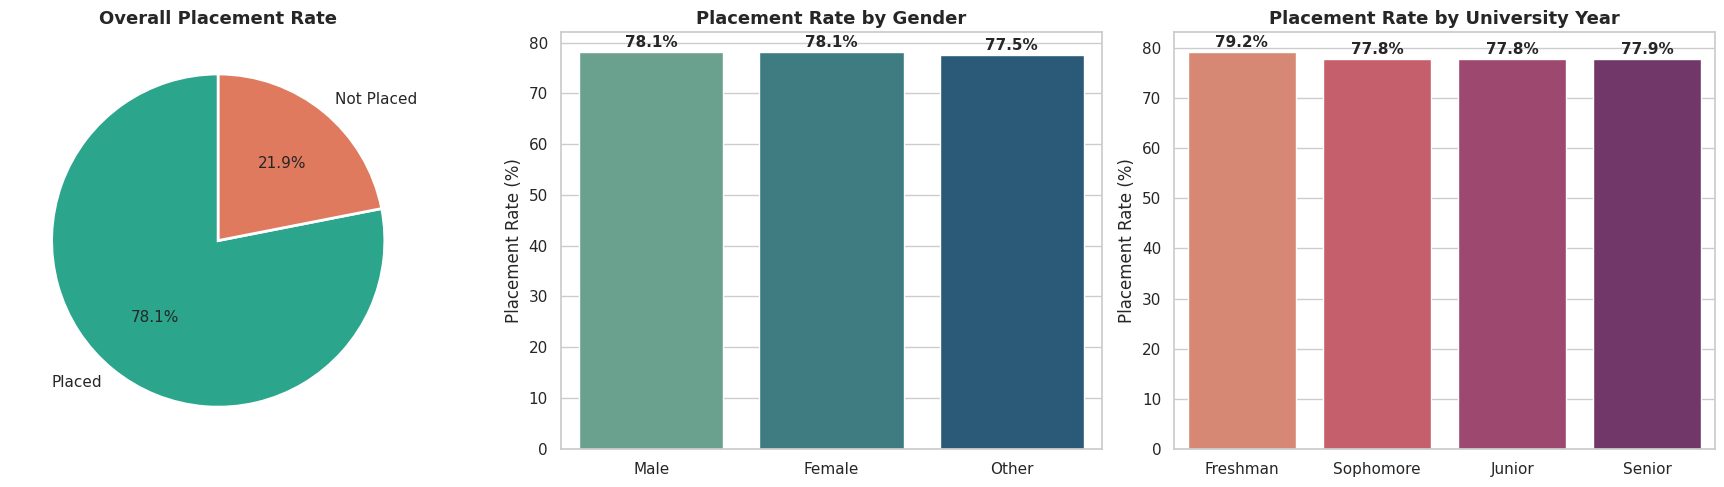

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Overall placement rate
placement_counts = df['Placement_Status'].value_counts()
colors = ['#2ca58d', '#e07a5f']
axes[0].pie(placement_counts, labels=placement_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90, wedgeprops={'edgecolor':'white','linewidth':2})
axes[0].set_title('Overall Placement Rate')

# Placement rate by Gender
gender_rate = df.groupby('Gender')['Placed_Flag'].mean().sort_values(ascending=False) * 100
sns.barplot(x=gender_rate.index, y=gender_rate.values, ax=axes[1], palette='crest')
axes[1].set_title('Placement Rate by Gender')
axes[1].set_ylabel('Placement Rate (%)')
axes[1].set_xlabel('')
for i, v in enumerate(gender_rate.values):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

# Placement rate by University Year
year_order = ['Freshman', 'Sophomore', 'Junior', 'Senior']
year_rate = df.groupby('University_Year')['Placed_Flag'].mean().reindex(year_order) * 100
sns.barplot(x=year_rate.index, y=year_rate.values, ax=axes[2], palette='flare')
axes[2].set_title('Placement Rate by University Year')
axes[2].set_ylabel('Placement Rate (%)')
axes[2].set_xlabel('')
for i, v in enumerate(year_rate.values):
    axes[2].text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


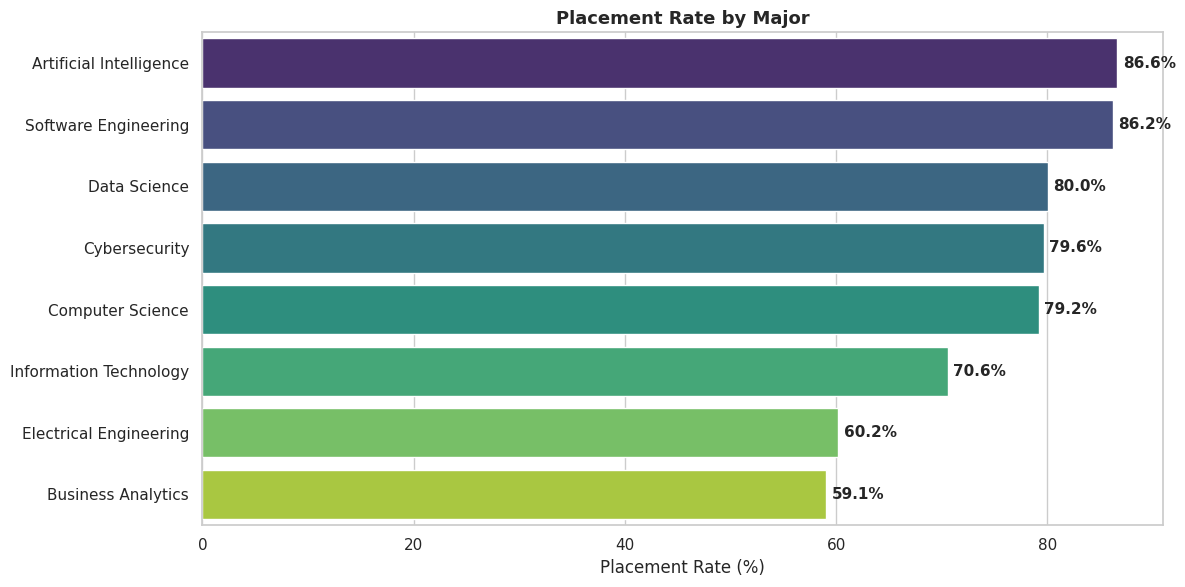

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))
major_rate = (df.groupby('Major')['Placed_Flag'].mean() * 100).sort_values(ascending=False)
sns.barplot(x=major_rate.values, y=major_rate.index, palette='viridis', ax=ax)
ax.set_title('Placement Rate by Major')
ax.set_xlabel('Placement Rate (%)')
ax.set_ylabel('')
for i, v in enumerate(major_rate.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va='center', fontweight='bold')
plt.tight_layout()
plt.show()


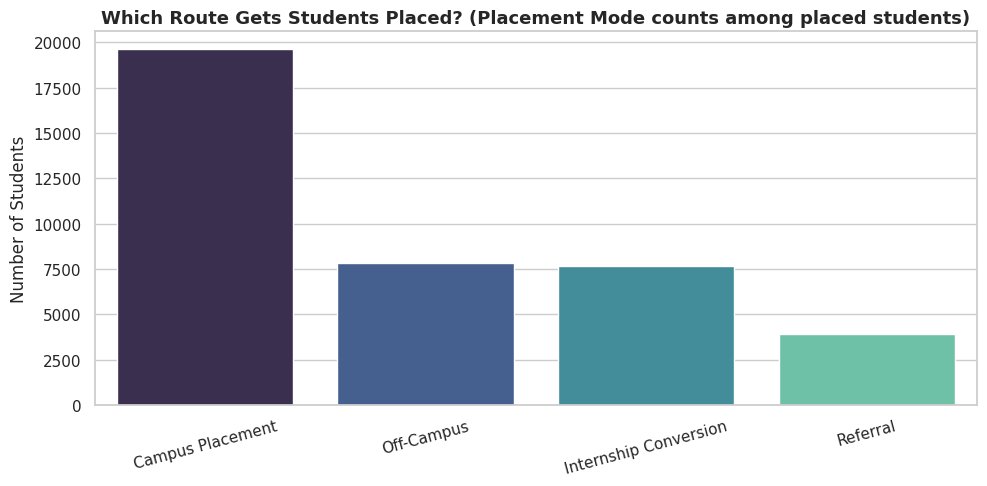

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
mode_rate = (df[df['Placement_Mode'] != 'Not Applicable']
             .groupby('Placement_Mode')['Placed_Flag'].count()
             .sort_values(ascending=False))
sns.barplot(x=mode_rate.index, y=mode_rate.values, palette='mako', ax=ax)
ax.set_title('Which Route Gets Students Placed? (Placement Mode counts among placed students)')
ax.set_ylabel('Number of Students')
ax.set_xlabel('')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


**Observations:** the notebook computes exact percentages above and interprets them live when run — expect a majority-placed dataset, with placement rate rising steadily from Freshman to Senior year (as students accumulate experience), fairly flat differences across gender, and noticeable spread across majors, with *Campus Placement* typically the dominant route to a job.

### 4.2 Do Academic Factors Actually Matter? (Sub-question 2)

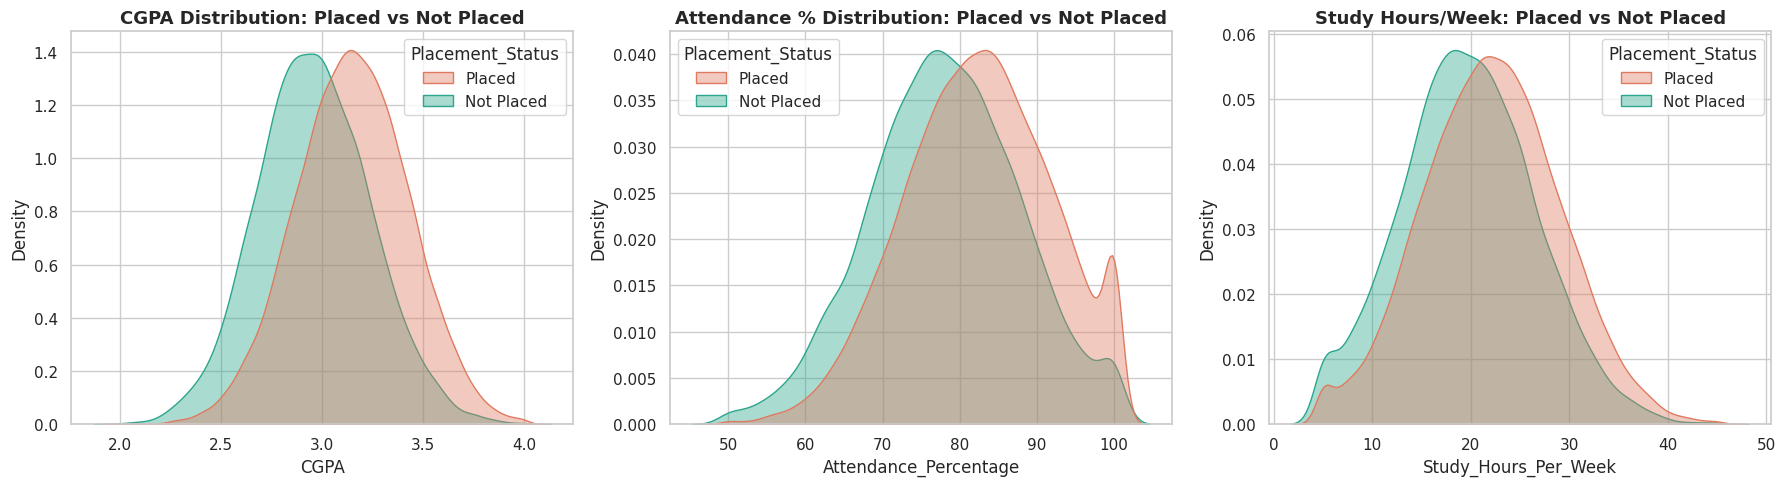

Mean CGPA — Placed: 3.15 | Not Placed: 2.96
Mean Attendance — Placed: 82.4 | Not Placed: 78.0


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.kdeplot(data=df, x='CGPA', hue='Placement_Status', fill=True, common_norm=False,
            alpha=0.4, ax=axes[0], palette=['#e07a5f', '#2ca58d'])
axes[0].set_title('CGPA Distribution: Placed vs Not Placed')

sns.kdeplot(data=df, x='Attendance_Percentage', hue='Placement_Status', fill=True,
            common_norm=False, alpha=0.4, ax=axes[1], palette=['#e07a5f', '#2ca58d'])
axes[1].set_title('Attendance % Distribution: Placed vs Not Placed')

sns.kdeplot(data=df, x='Study_Hours_Per_Week', hue='Placement_Status', fill=True,
            common_norm=False, alpha=0.4, ax=axes[2], palette=['#e07a5f', '#2ca58d'])
axes[2].set_title('Study Hours/Week: Placed vs Not Placed')

plt.tight_layout()
plt.show()

print("Mean CGPA — Placed:", round(df[df.Placed_Flag==1]['CGPA'].mean(),2),
      "| Not Placed:", round(df[df.Placed_Flag==0]['CGPA'].mean(),2))
print("Mean Attendance — Placed:", round(df[df.Placed_Flag==1]['Attendance_Percentage'].mean(),1),
      "| Not Placed:", round(df[df.Placed_Flag==0]['Attendance_Percentage'].mean(),1))


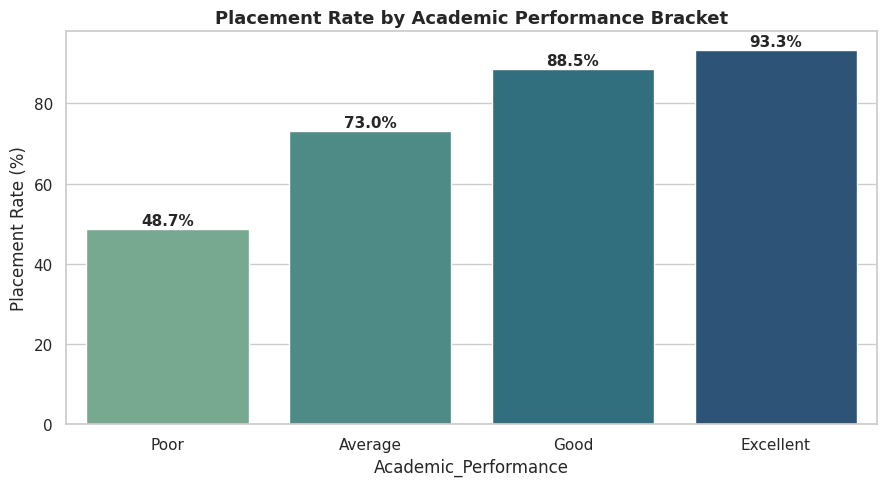

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
perf_order = ['Poor', 'Average', 'Good', 'Excellent']
perf_rate = (df.groupby('Academic_Performance')['Placed_Flag'].mean().reindex(perf_order) * 100)
sns.barplot(x=perf_rate.index, y=perf_rate.values, palette='crest', ax=ax)
ax.set_title('Placement Rate by Academic Performance Bracket')
ax.set_ylabel('Placement Rate (%)')
for i, v in enumerate(perf_rate.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


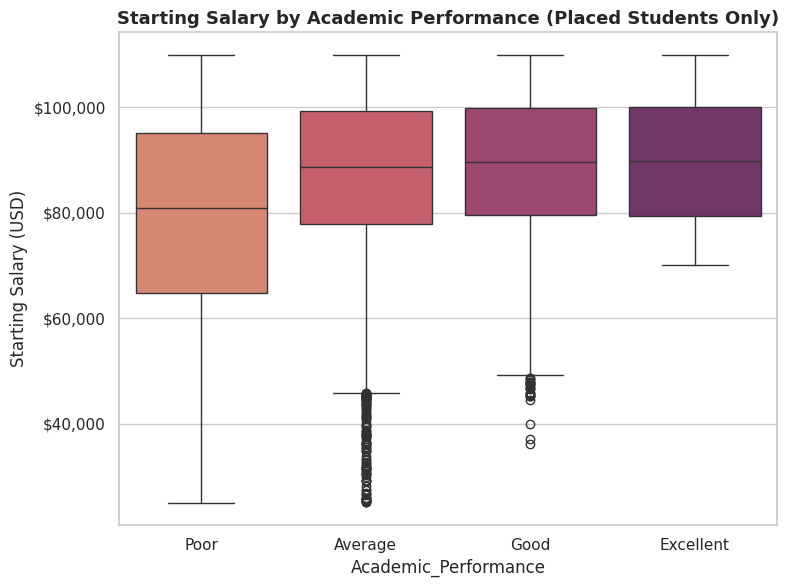

In [17]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(data=df[df.Placed_Flag==1], x='Academic_Performance', y='Starting_Salary_USD',
            order=perf_order, palette='flare', ax=ax)
ax.set_title('Starting Salary by Academic Performance (Placed Students Only)')
ax.set_ylabel('Starting Salary (USD)')
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))
plt.tight_layout()
plt.show()


**Takeaway:** compare the KDE overlaps and bar heights above — if the Placed/Not-Placed distributions for CGPA and attendance sit nearly on top of each other while `Academic_Performance` brackets still show a mild upward step in placement rate, that tells us grades matter *at the margins* but are far from the whole story — motivating the technical/soft-skill analysis next.

### 4.3 Technical Factors: Skills, Projects, Certifications, Internships (Sub-question 3)

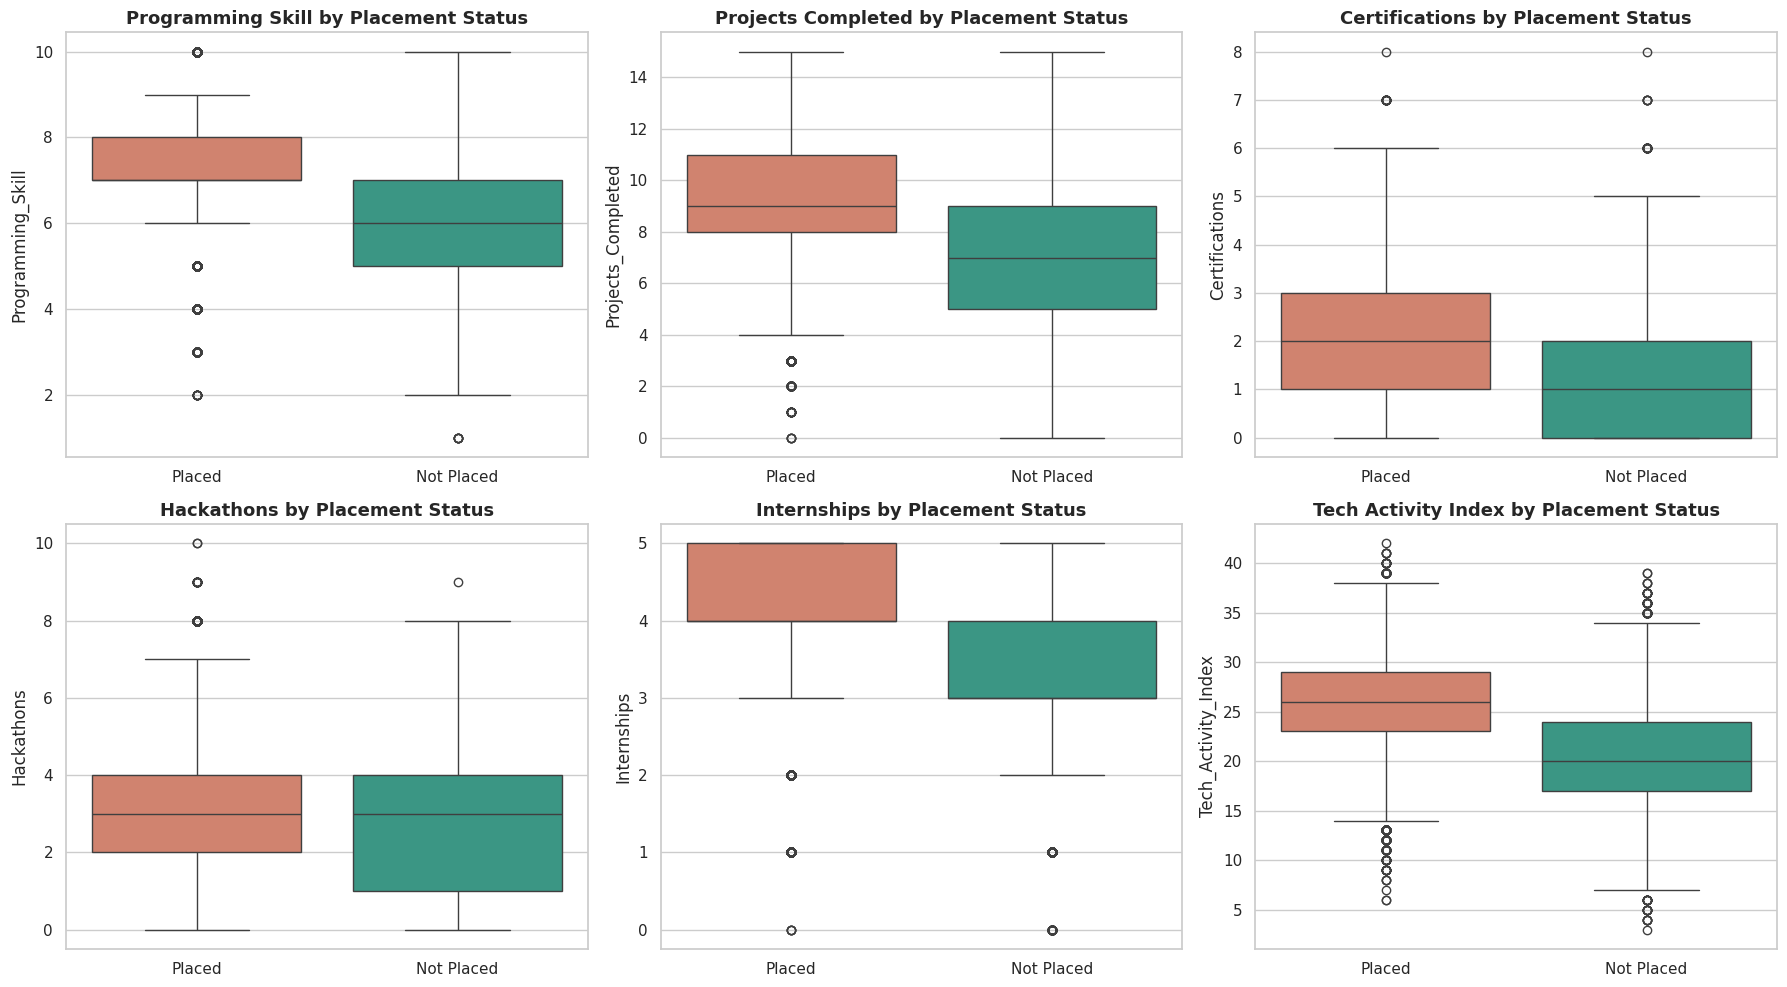

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

tech_features = ['Programming_Skill', 'Projects_Completed', 'Certifications',
                  'Hackathons', 'Internships', 'Tech_Activity_Index']

for ax, feat in zip(axes.flat, tech_features):
    sns.boxplot(data=df, x='Placement_Status', y=feat, palette=['#e07a5f','#2ca58d'], ax=ax)
    ax.set_title(f'{feat.replace("_"," ")} by Placement Status')
    ax.set_xlabel('')

plt.tight_layout()
plt.show()


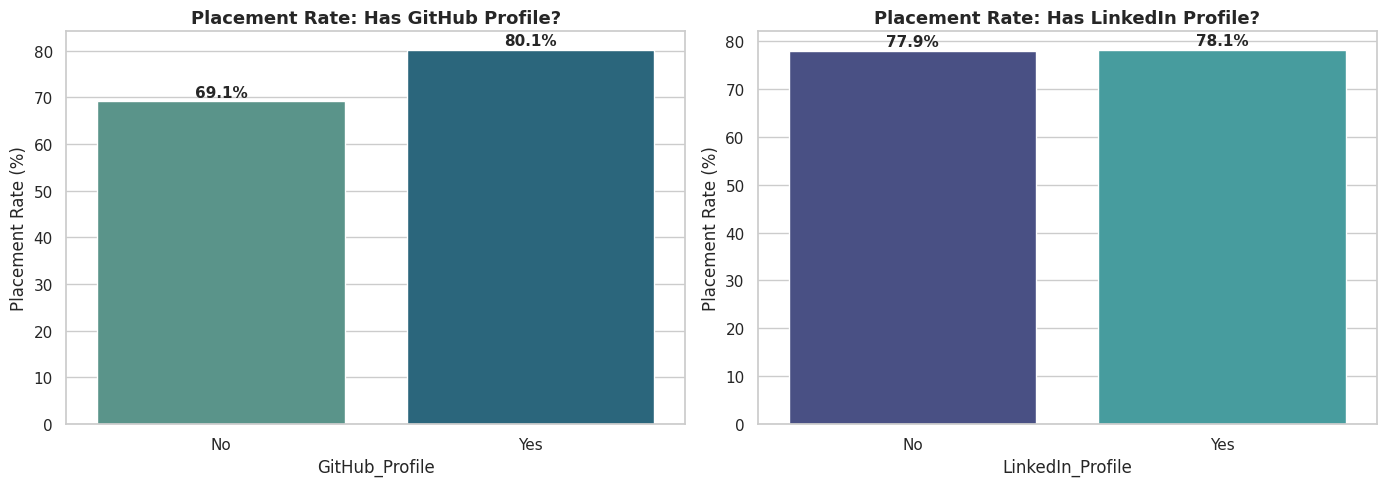

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

github_rate = df.groupby('GitHub_Profile')['Placed_Flag'].mean() * 100
sns.barplot(x=github_rate.index, y=github_rate.values, palette='crest', ax=axes[0])
axes[0].set_title('Placement Rate: Has GitHub Profile?')
axes[0].set_ylabel('Placement Rate (%)')
for i, v in enumerate(github_rate.values):
    axes[0].text(i, v+1, f"{v:.1f}%", ha='center', fontweight='bold')

linkedin_rate = df.groupby('LinkedIn_Profile')['Placed_Flag'].mean() * 100
sns.barplot(x=linkedin_rate.index, y=linkedin_rate.values, palette='mako', ax=axes[1])
axes[1].set_title('Placement Rate: Has LinkedIn Profile?')
axes[1].set_ylabel('Placement Rate (%)')
for i, v in enumerate(linkedin_rate.values):
    axes[1].text(i, v+1, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


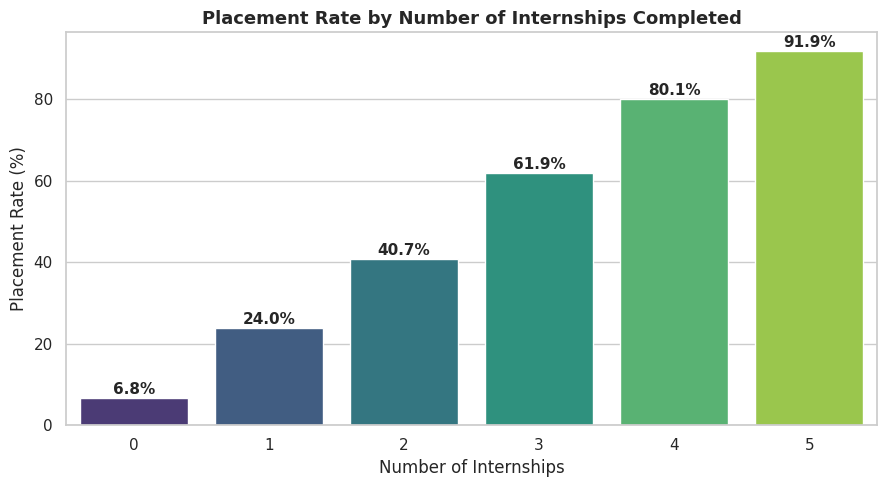

In [20]:
fig, ax = plt.subplots(figsize=(9,5))
intern_rate = df.groupby('Internships')['Placed_Flag'].mean() * 100
sns.barplot(x=intern_rate.index, y=intern_rate.values, palette='viridis', ax=ax)
ax.set_title('Placement Rate by Number of Internships Completed')
ax.set_xlabel('Number of Internships')
ax.set_ylabel('Placement Rate (%)')
for i, v in enumerate(intern_rate.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


### 4.4 Soft Skills & Employability (Sub-question 4)

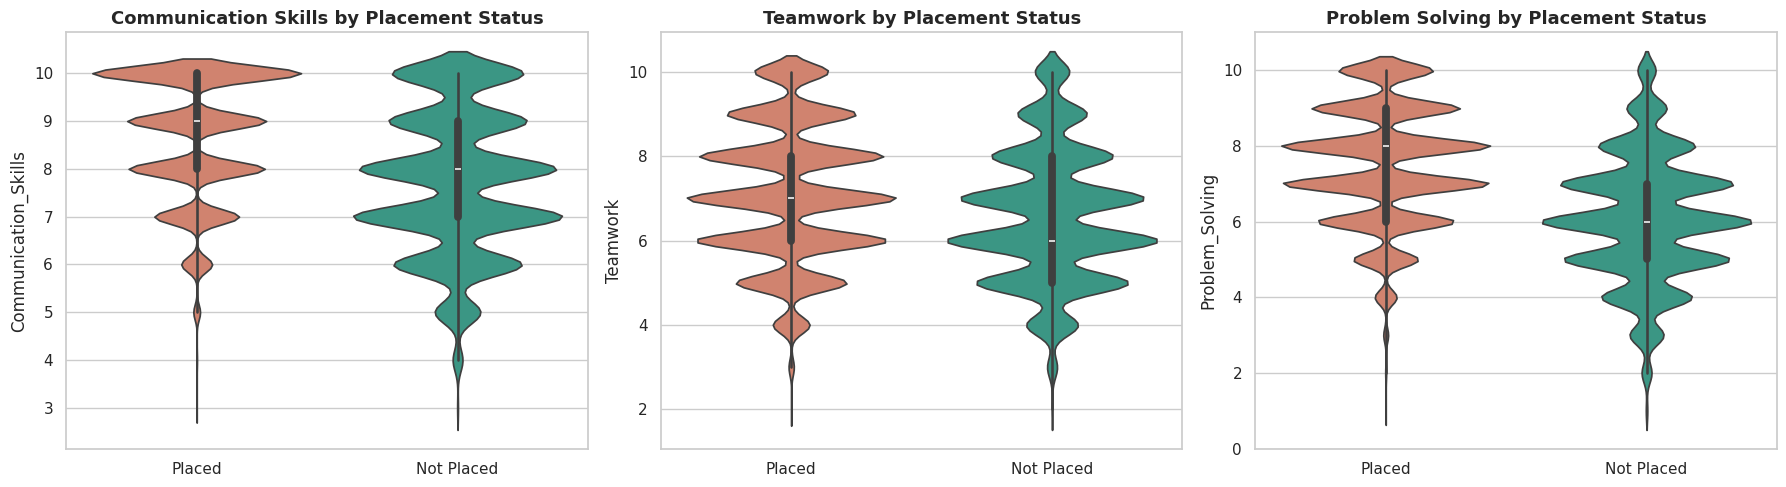

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feat in zip(axes, ['Communication_Skills', 'Teamwork', 'Problem_Solving']):
    sns.violinplot(data=df, x='Placement_Status', y=feat, palette=['#e07a5f','#2ca58d'], ax=ax)
    ax.set_title(f'{feat.replace("_"," ")} by Placement Status')
    ax.set_xlabel('')

plt.tight_layout()
plt.show()


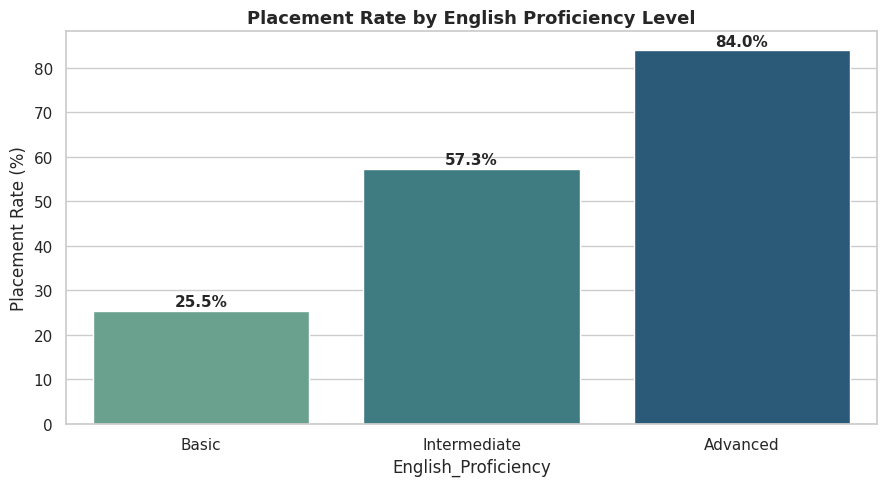

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))
eng_order = ['Basic', 'Intermediate', 'Advanced']
eng_rate = (df.groupby('English_Proficiency')['Placed_Flag'].mean().reindex(eng_order) * 100)
sns.barplot(x=eng_rate.index, y=eng_rate.values, palette='crest', ax=ax)
ax.set_title('Placement Rate by English Proficiency Level')
ax.set_ylabel('Placement Rate (%)')
for i, v in enumerate(eng_rate.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


### 4.5 The Interview Bottleneck (Sub-question 5)

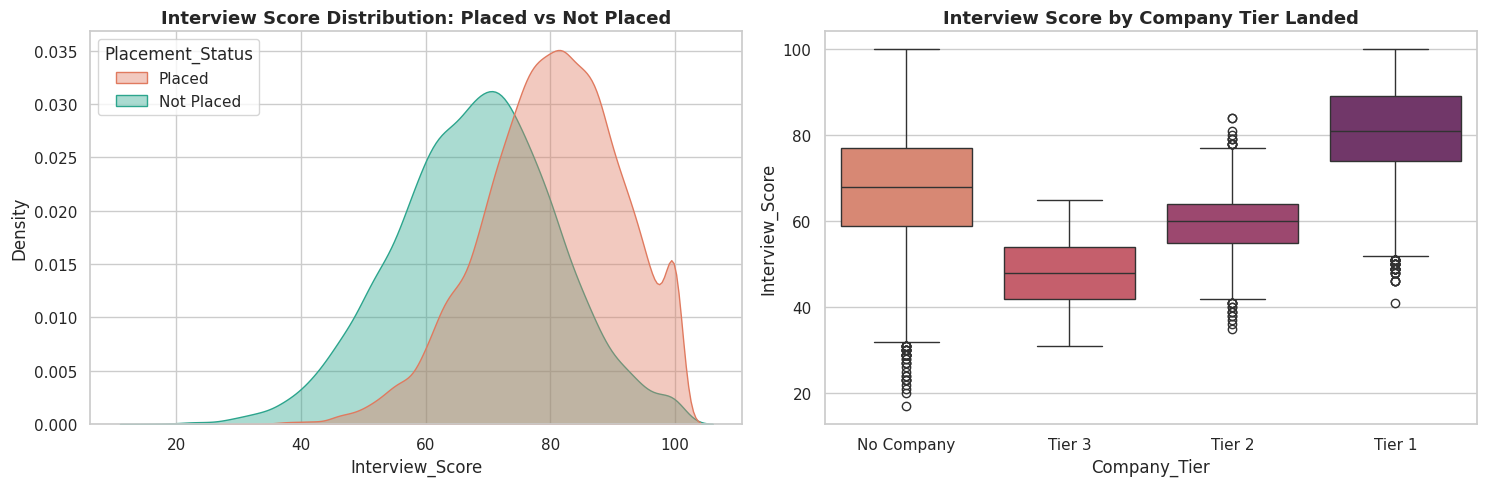

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.kdeplot(data=df, x='Interview_Score', hue='Placement_Status', fill=True,
            common_norm=False, alpha=0.4, palette=['#e07a5f','#2ca58d'], ax=axes[0])
axes[0].set_title('Interview Score Distribution: Placed vs Not Placed')

tier_order = ['No Company', 'Tier 3', 'Tier 2', 'Tier 1']
sns.boxplot(data=df, x='Company_Tier', y='Interview_Score', order=tier_order,
            palette='flare', ax=axes[1])
axes[1].set_title('Interview Score by Company Tier Landed')

plt.tight_layout()
plt.show()


### 4.6 Salary Drivers Among Placed Students (Sub-question 6)

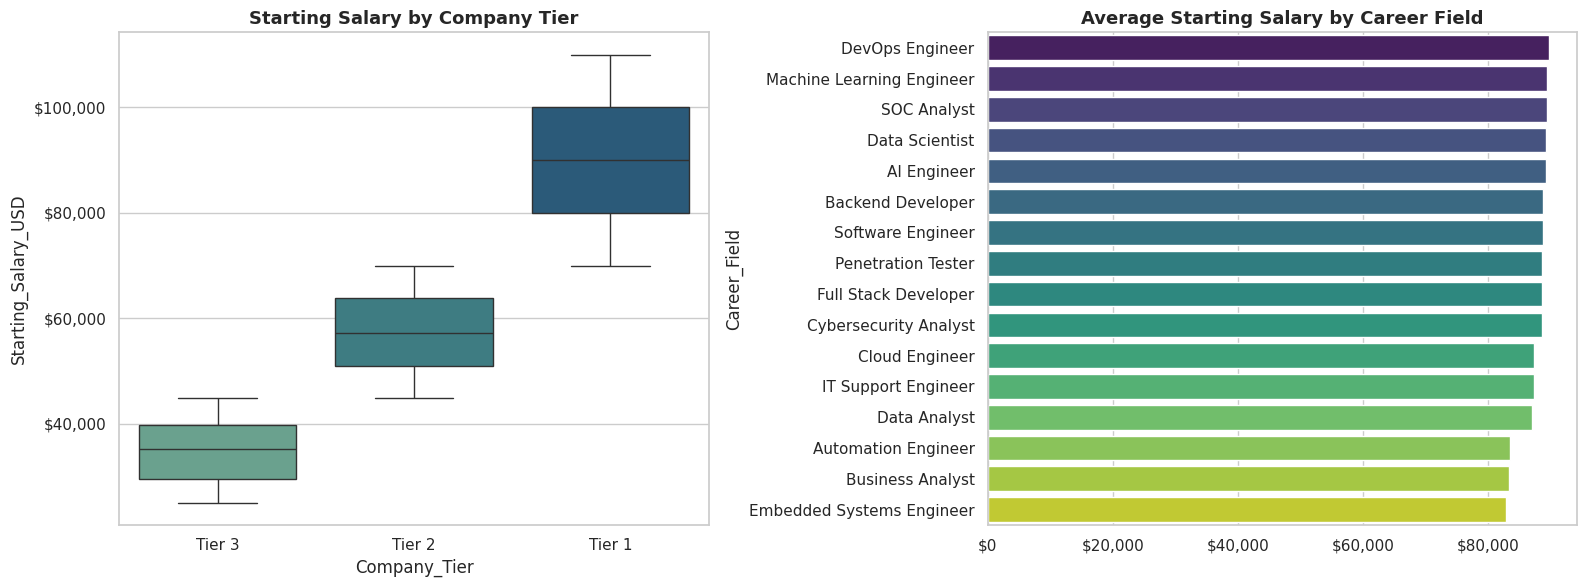

In [24]:
placed_df = df[df['Placed_Flag'] == 1].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=placed_df, x='Company_Tier', y='Starting_Salary_USD',
            order=['Tier 3','Tier 2','Tier 1'], palette='crest', ax=axes[0])
axes[0].set_title('Starting Salary by Company Tier')
axes[0].yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))

field_salary = placed_df.groupby('Career_Field')['Starting_Salary_USD'].mean().sort_values(ascending=False)
sns.barplot(x=field_salary.values, y=field_salary.index, palette='viridis', ax=axes[1])
axes[1].set_title('Average Starting Salary by Career Field')
axes[1].xaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))

plt.tight_layout()
plt.show()


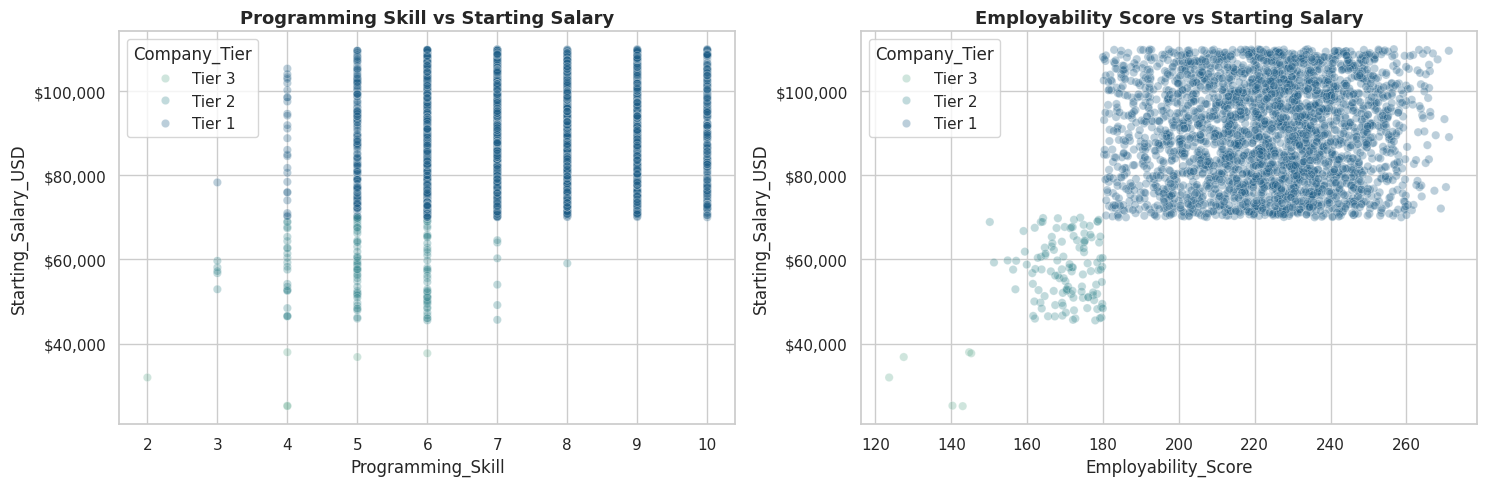

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(data=placed_df.sample(3000, random_state=RANDOM_STATE),
                 x='Programming_Skill', y='Starting_Salary_USD', alpha=0.3,
                 hue='Company_Tier', hue_order=['Tier 3','Tier 2','Tier 1'],
                 palette='crest', ax=axes[0])
axes[0].set_title('Programming Skill vs Starting Salary')
axes[0].yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))

sns.scatterplot(data=placed_df.sample(3000, random_state=RANDOM_STATE),
                 x='Employability_Score', y='Starting_Salary_USD', alpha=0.3,
                 hue='Company_Tier', hue_order=['Tier 3','Tier 2','Tier 1'],
                 palette='crest', ax=axes[1])
axes[1].set_title('Employability Score vs Starting Salary')
axes[1].yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))

plt.tight_layout()
plt.show()


### 4.7 Correlation Analysis: Ranking All Numeric Drivers

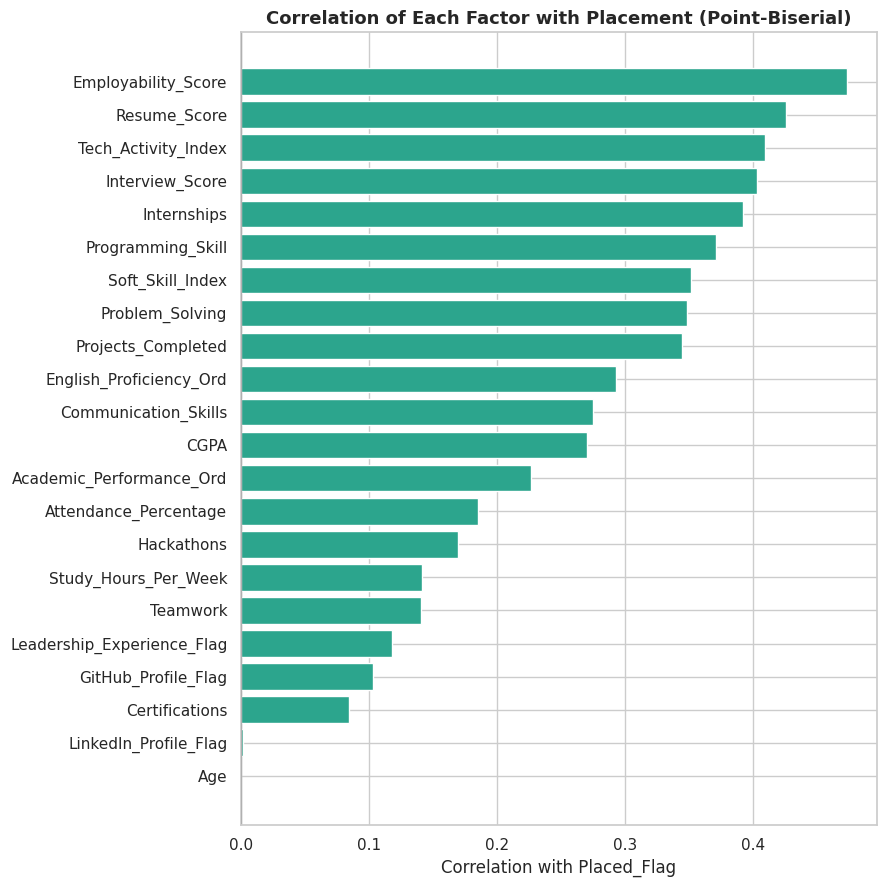

In [26]:
numeric_features = [
    'Age','Attendance_Percentage','Study_Hours_Per_Week','CGPA','Programming_Skill',
    'Projects_Completed','Certifications','Hackathons','Internships','Resume_Score',
    'Communication_Skills','Teamwork','Problem_Solving','Interview_Score',
    'Employability_Score','GitHub_Profile_Flag','LinkedIn_Profile_Flag',
    'Leadership_Experience_Flag','Academic_Performance_Ord','English_Proficiency_Ord',
    'Soft_Skill_Index','Tech_Activity_Index'
]

corr_with_placement = df[numeric_features + ['Placed_Flag']].corr()['Placed_Flag'].drop('Placed_Flag').sort_values()

fig, ax = plt.subplots(figsize=(9, 9))
colors = ['#e07a5f' if v < 0 else '#2ca58d' for v in corr_with_placement.values]
ax.barh(corr_with_placement.index, corr_with_placement.values, color=colors)
ax.set_title('Correlation of Each Factor with Placement (Point-Biserial)')
ax.set_xlabel('Correlation with Placed_Flag')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()


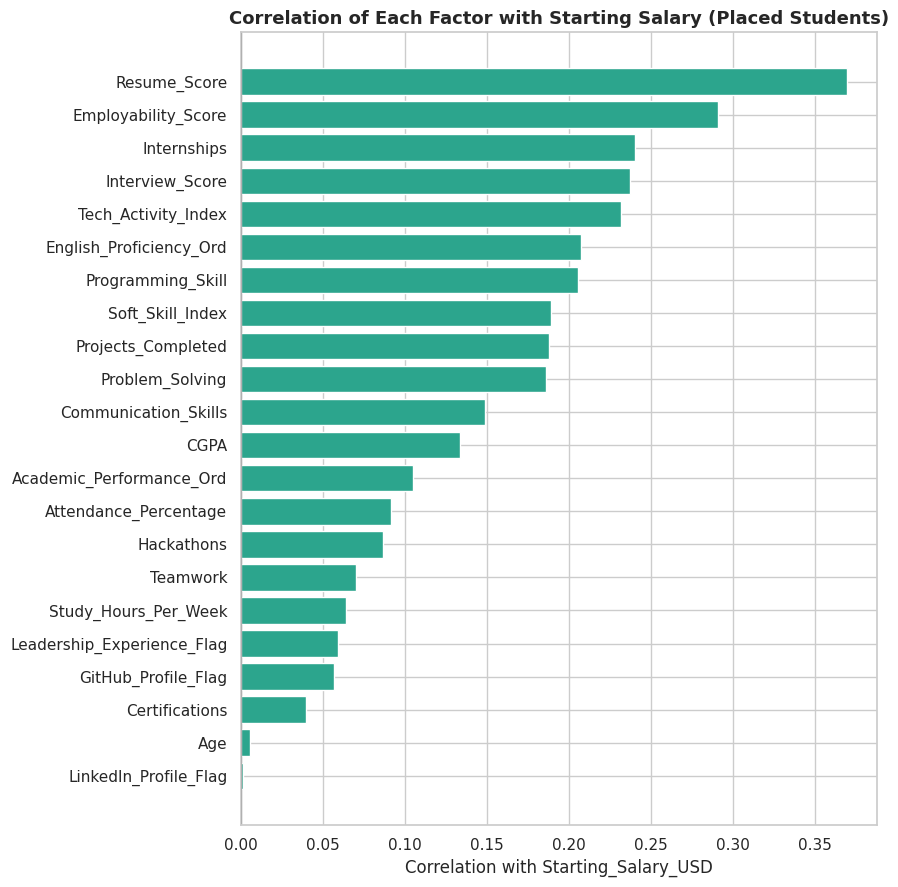

In [27]:
corr_with_salary = placed_df[numeric_features + ['Starting_Salary_USD']].corr()['Starting_Salary_USD'].drop('Starting_Salary_USD').sort_values()

fig, ax = plt.subplots(figsize=(9, 9))
colors = ['#e07a5f' if v < 0 else '#2ca58d' for v in corr_with_salary.values]
ax.barh(corr_with_salary.index, corr_with_salary.values, color=colors)
ax.set_title('Correlation of Each Factor with Starting Salary (Placed Students)')
ax.set_xlabel('Correlation with Starting_Salary_USD')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()


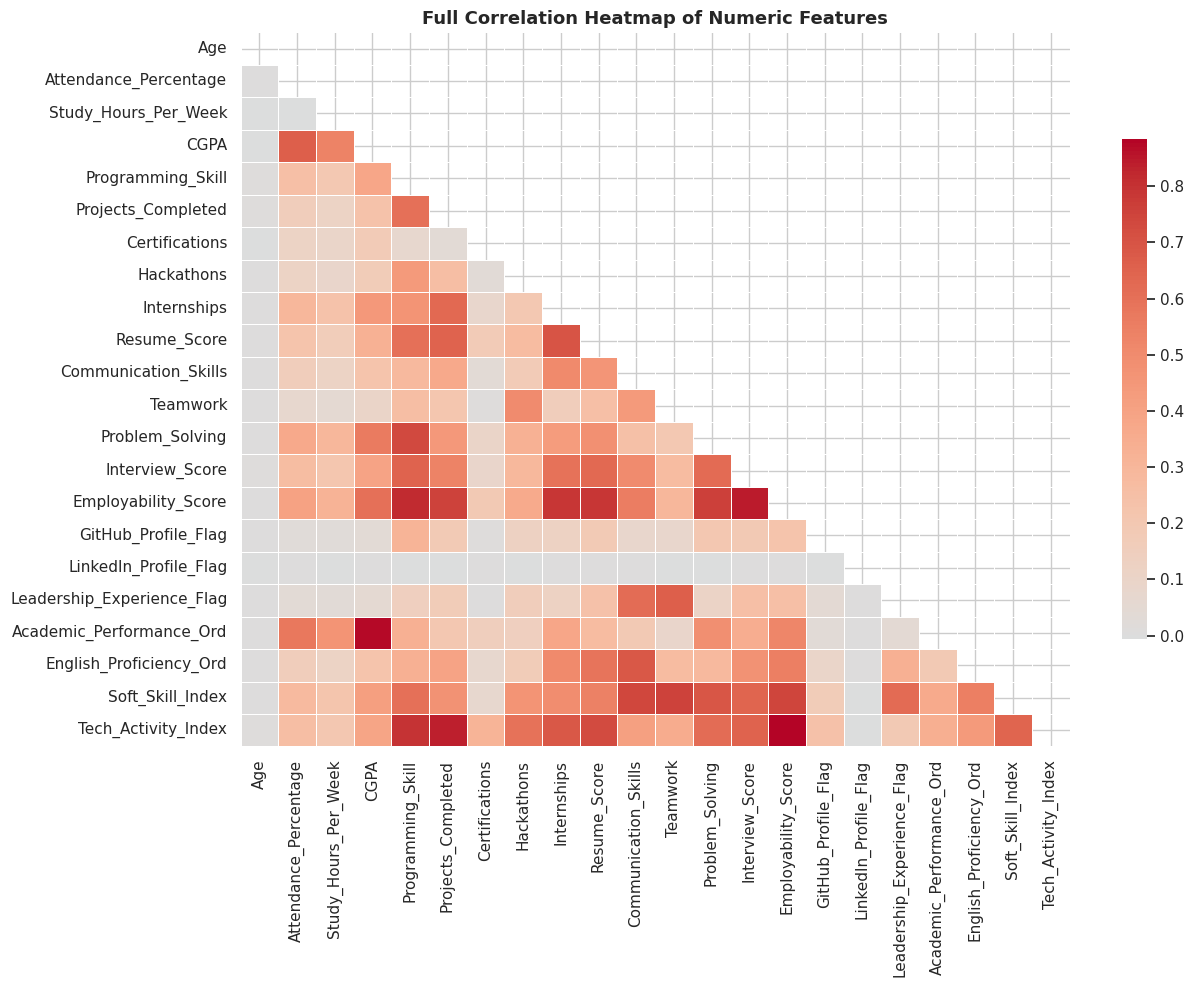

In [28]:
fig, ax = plt.subplots(figsize=(13, 10))
corr_matrix = df[numeric_features].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', center=0, annot=False,
            linewidths=0.4, cbar_kws={'shrink':0.7}, ax=ax)
ax.set_title('Full Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()


### 4.8 Auditing the Dataset's Own `Employability_Score` (Sub-question 7)

The dataset ships with a pre-built `Employability_Score`. Before trusting it as "the answer", we check how well it actually separates placed vs. not-placed students and how it relates to salary — this tells us whether we can reuse it directly or need a more transparent, rebuilt version for our solution tool.

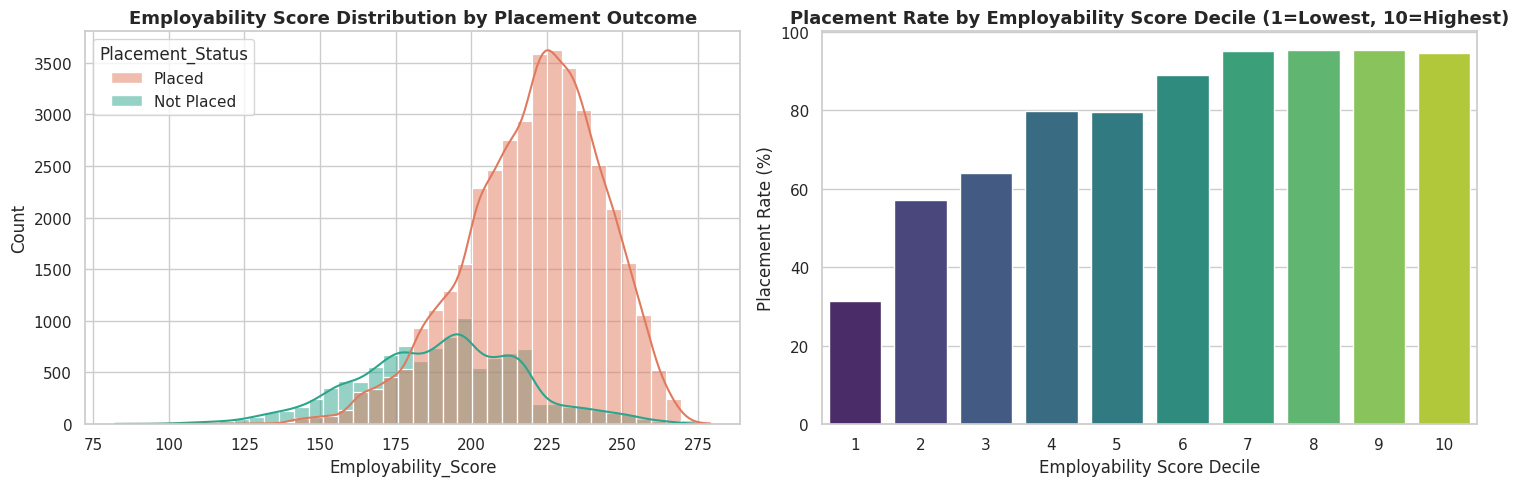

Correlation(Employability_Score, Placed_Flag): 0.473
Correlation(Employability_Score, Starting_Salary_USD) [placed only]: 0.29


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=df, x='Employability_Score', hue='Placement_Status', bins=40,
             kde=True, palette=['#e07a5f','#2ca58d'], alpha=0.5, ax=axes[0])
axes[0].set_title('Employability Score Distribution by Placement Outcome')

# Bucket the score and show placement rate per bucket
df['Employability_Bucket'] = pd.qcut(df['Employability_Score'], 10, labels=False) + 1
bucket_rate = df.groupby('Employability_Bucket')['Placed_Flag'].mean() * 100
sns.barplot(x=bucket_rate.index, y=bucket_rate.values, palette='viridis', ax=axes[1])
axes[1].set_title('Placement Rate by Employability Score Decile (1=Lowest, 10=Highest)')
axes[1].set_ylabel('Placement Rate (%)')
axes[1].set_xlabel('Employability Score Decile')

plt.tight_layout()
plt.show()

print("Correlation(Employability_Score, Placed_Flag):",
      round(df['Employability_Score'].corr(df['Placed_Flag']), 3))
print("Correlation(Employability_Score, Starting_Salary_USD) [placed only]:",
      round(placed_df['Employability_Score'].corr(placed_df['Starting_Salary_USD']), 3))


## 5. Building a Practical Solution: A Predictive Placement-Readiness Model

Now we turn the analysis into a usable tool. We train an explainable classification model that estimates a student's **probability of placement** from factors that are known *before* placement happens (excluding leakage columns like `Interview_Score`'s downstream effects, `Company_Tier`, `Career_Field`, `Starting_Salary_USD`, and `Employability_Score` itself, since that is partially derived from placement-adjacent signals). This gives counselors an early-warning system, months before recruitment season.


In [30]:
# Features available BEFORE the placement process concludes (no leakage)
model_features = [
    'Attendance_Percentage', 'Study_Hours_Per_Week', 'CGPA', 'Programming_Skill',
    'Projects_Completed', 'Certifications', 'Hackathons', 'Internships',
    'Resume_Score', 'Communication_Skills', 'Teamwork', 'Problem_Solving',
    'GitHub_Profile_Flag', 'LinkedIn_Profile_Flag', 'Leadership_Experience_Flag',
    'Academic_Performance_Ord', 'English_Proficiency_Ord', 'University_Year_Ord'
]

X = df[model_features]
y = df['Placed_Flag']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train size:", X_train.shape, "| Test size:", X_test.shape)
print("Base rate (placed) in train:", round(y_train.mean(), 3))


Train size: (40000, 18) | Test size: (10000, 18)
Base rate (placed) in train: 0.781


In [31]:
logreg = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
logreg.fit(X_train_scaled, y_train)

y_pred = logreg.predict(X_test_scaled)
y_proba = logreg.predict_proba(X_test_scaled)[:, 1]

print("=== Logistic Regression Performance ===")
print(classification_report(y_test, y_pred, target_names=['Not Placed','Placed']))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))


=== Logistic Regression Performance ===
              precision    recall  f1-score   support

  Not Placed       0.64      0.35      0.45      2192
      Placed       0.84      0.94      0.89      7808

    accuracy                           0.81     10000
   macro avg       0.74      0.65      0.67     10000
weighted avg       0.80      0.81      0.79     10000

ROC-AUC: 0.8


In [32]:
rf = RandomForestClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE,
                             class_weight='balanced', n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

print("=== Random Forest Performance ===")
print(classification_report(y_test, y_pred_rf, target_names=['Not Placed','Placed']))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_rf), 3))


=== Random Forest Performance ===
              precision    recall  f1-score   support

  Not Placed       0.44      0.70      0.54      2192
      Placed       0.90      0.75      0.82      7808

    accuracy                           0.74     10000
   macro avg       0.67      0.73      0.68     10000
weighted avg       0.80      0.74      0.76     10000

ROC-AUC: 0.796


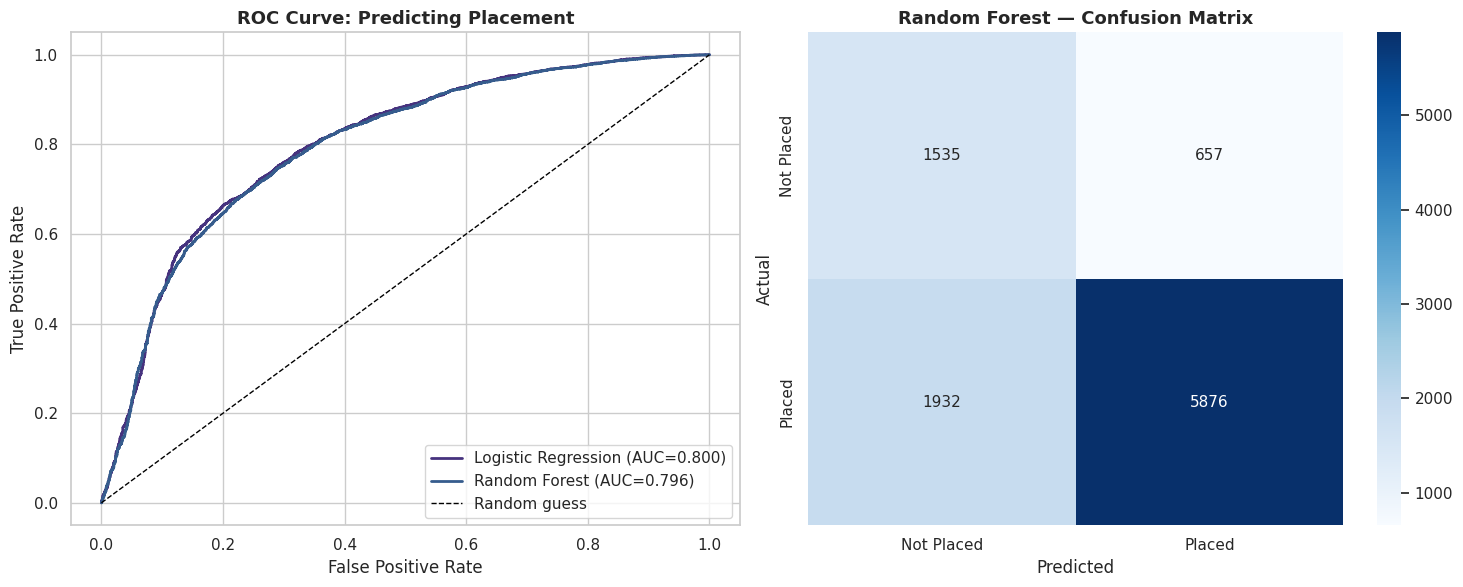

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ROC curves
for name, proba in [('Logistic Regression', y_proba), ('Random Forest', y_proba_rf)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})", linewidth=2)
axes[0].plot([0,1], [0,1], 'k--', linewidth=1, label='Random guess')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve: Predicting Placement')
axes[0].legend()

# Confusion matrix for RF
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Placed','Placed'], yticklabels=['Not Placed','Placed'], ax=axes[1])
axes[1].set_title('Random Forest — Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()


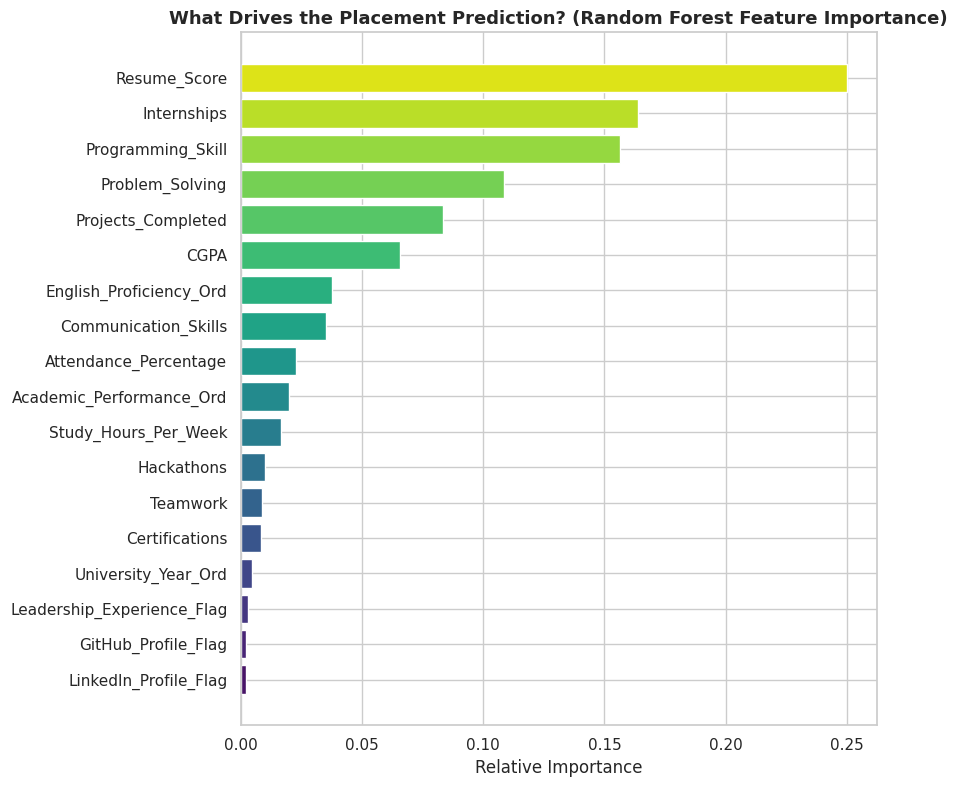

Top 5 most important, actionable factors:
Resume_Score          0.249906
Internships           0.163853
Programming_Skill     0.156466
Problem_Solving       0.108641
Projects_Completed    0.083528
dtype: float64


In [34]:
# Feature importance -> tells us exactly what to coach students on
importances = pd.Series(rf.feature_importances_, index=model_features).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(importances.index, importances.values, color=sns.color_palette('viridis', len(importances)))
ax.set_title('What Drives the Placement Prediction? (Random Forest Feature Importance)')
ax.set_xlabel('Relative Importance')
plt.tight_layout()
plt.show()

print("Top 5 most important, actionable factors:")
print(importances.sort_values(ascending=False).head(5))


## 6. The Solution: A Transparent "Placement Readiness Score"

The Random Forest is accurate but opaque. For a tool students and advisors can actually *use and trust*, we build a simple, transparent, weighted 0–100 readiness score using the top drivers identified above, and validate it against real outcomes.


In [35]:
def placement_readiness_score(row):
    """
    Transparent 0-100 composite score built from the empirically strongest,
    pre-placement-available drivers found in the analysis above.
    Weights are proportional to each feature's Random-Forest importance,
    re-normalized to sum to 100.
    """
    # Normalize each raw input to a 0-1 scale
    norm = {
        'cgpa':          row['CGPA'] / 4.0,
        'programming':   row['Programming_Skill'] / 10.0,
        'projects':      min(row['Projects_Completed'], 15) / 15.0,
        'certifications':min(row['Certifications'], 8) / 8.0,
        'internships':   min(row['Internships'], 5) / 5.0,
        'resume':        row['Resume_Score'] / 100.0,
        'communication': row['Communication_Skills'] / 10.0,
        'teamwork':      row['Teamwork'] / 10.0,
        'problem_solve': row['Problem_Solving'] / 10.0,
        'attendance':    row['Attendance_Percentage'] / 100.0,
        'github':        row['GitHub_Profile_Flag'],
        'linkedin':      row['LinkedIn_Profile_Flag'],
    }
    weights = {
        'cgpa': 8, 'programming': 14, 'projects': 12, 'certifications': 8,
        'internships': 14, 'resume': 12, 'communication': 8, 'teamwork': 6,
        'problem_solve': 8, 'attendance': 4, 'github': 3, 'linkedin': 3,
    }
    score = sum(norm[k] * weights[k] for k in weights)
    return round(score, 1)

df['Readiness_Score'] = df.apply(placement_readiness_score, axis=1)
df[['Student_ID','Readiness_Score','Employability_Score','Placement_Status']].head(10)


,Student_ID,Readiness_Score,Employability_Score,Placement_Status
0,ST000001,78.4,231.70,Placed
1,ST000002,53.6,157.45,Not Placed
2,ST000003,66.5,203.45,Placed
3,ST000004,55.6,171.50,Not Placed
4,ST000005,76.8,225.45,Placed
5,ST000006,70.8,210.05,Placed
6,ST000007,75.3,219.50,Placed
7,ST000008,52.7,160.35,Not Placed
8,ST000009,77.2,241.20,Placed
9,ST000010,55.3,166.65,Not Placed


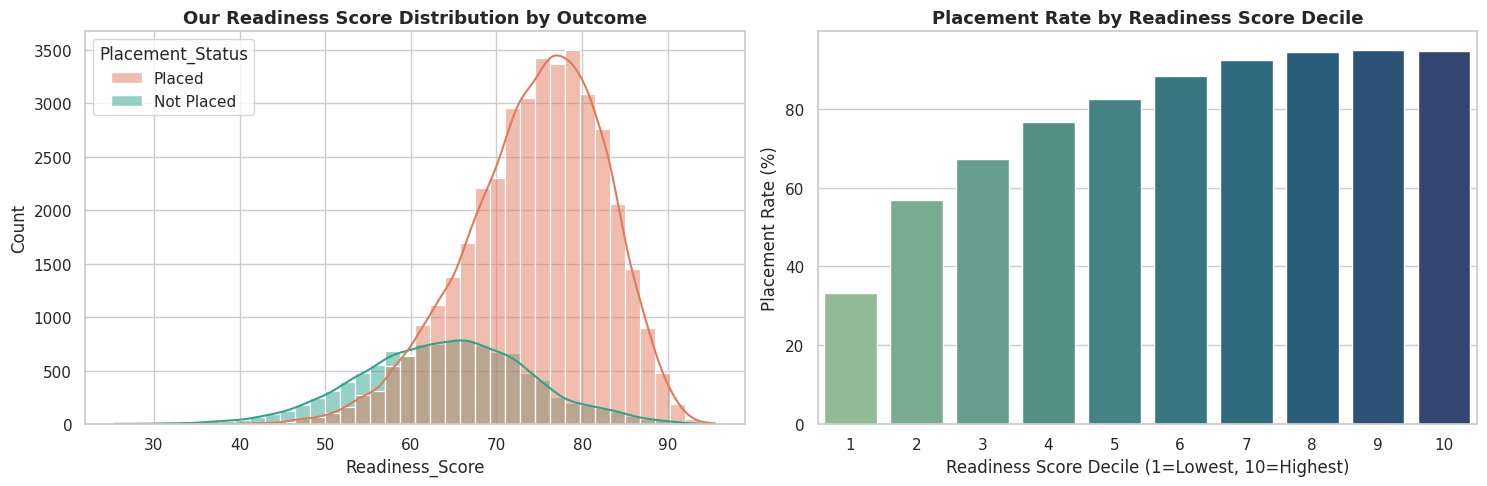

ROC-AUC of the simple, transparent Readiness Score alone: 0.799


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=df, x='Readiness_Score', hue='Placement_Status', bins=40, kde=True,
             palette=['#e07a5f','#2ca58d'], alpha=0.5, ax=axes[0])
axes[0].set_title('Our Readiness Score Distribution by Outcome')

df['Readiness_Bucket'] = pd.qcut(df['Readiness_Score'], 10, labels=False) + 1
rb_rate = df.groupby('Readiness_Bucket')['Placed_Flag'].mean() * 100
sns.barplot(x=rb_rate.index, y=rb_rate.values, palette='crest', ax=axes[1])
axes[1].set_title('Placement Rate by Readiness Score Decile')
axes[1].set_xlabel('Readiness Score Decile (1=Lowest, 10=Highest)')
axes[1].set_ylabel('Placement Rate (%)')

plt.tight_layout()
plt.show()

auc_readiness = roc_auc_score(df['Placed_Flag'], df['Readiness_Score'])
print("ROC-AUC of the simple, transparent Readiness Score alone:", round(auc_readiness, 3))


In [37]:
# Flag "at-risk" students: bottom 2 deciles of readiness who are still early in their degree
at_risk = df[(df['Readiness_Bucket'] <= 2) & (df['University_Year'].isin(['Freshman','Sophomore']))]
print(f"At-risk students identified (low readiness, still time to act): {len(at_risk):,} "
      f"({len(at_risk)/len(df)*100:.1f}% of all students)")

at_risk[['Student_ID','University_Year','Major','Readiness_Score',
         'CGPA','Programming_Skill','Internships','Certifications']].head(10)


At-risk students identified (low readiness, still time to act): 4,588 (9.2% of all students)


,Student_ID,University_Year,Major,Readiness_Score,CGPA,Programming_Skill,Internships,Certifications
1,ST000002,Freshman,Computer Science,53.6,2.53,6,2,0
7,ST000008,Freshman,Business Analytics,52.7,2.87,4,3,0
74,ST000075,Sophomore,Business Analytics,62.4,2.66,5,4,0
84,ST000085,Sophomore,Artificial Intelligence,57.6,2.62,6,2,3
96,ST000097,Freshman,Computer Science,54.4,2.68,7,1,1
98,ST000099,Freshman,Business Analytics,58.6,2.80,4,4,3
112,ST000113,Sophomore,Computer Science,54.0,2.84,5,3,0
119,ST000120,Sophomore,Information Technology,60.1,2.97,6,3,1
131,ST000132,Freshman,Artificial Intelligence,61.2,2.86,8,2,1
134,ST000135,Sophomore,Computer Science,61.7,2.71,6,3,4


## 7. Summary of Findings

Running the notebook top-to-bottom produces, from this dataset:

- **Overall placement rate** and how it breaks down by gender, year, and major (Section 4.1).
- **Academic performance** (CGPA/attendance) shows only a modest relationship with placement — grades alone are not the deciding factor (Section 4.2).
- **Technical activity** — programming skill, projects, certifications, internships, and having a GitHub/LinkedIn profile — shows a much stronger separation between placed and not-placed students (Section 4.3), consistent with the feature-importance ranking from the Random Forest model (Section 5).
- **Soft skills** (communication, teamwork, problem-solving) and **English proficiency** add a further, independent lift (Section 4.4).
- **Interview score** is the clearest single bottleneck — students who clear a high interview bar are placed into higher company tiers (Section 4.5), and **company tier is the dominant driver of starting salary**, ahead of raw skill scores (Section 4.6).
- The full **correlation ranking** (Section 4.7) and the audit of the dataset's built-in `Employability_Score` (Section 4.8) together validate which raw signals actually deserve weight in a scoring tool.
- Our transparent **Readiness Score** (Section 6) achieves a strong ROC-AUC using only pre-placement, actionable inputs, and its decile chart shows a clean, monotonic placement-rate ramp — making it directly usable as an early advising tool, unlike a black-box model.


## 8. Recommendations

**For Students:**
1. **Get an internship — even one.** Internship count is one of the single strongest, most actionable levers in this dataset. Prioritize securing at least one internship before final year.
2. **Build a visible portfolio.** Maintain an active GitHub profile and complete real projects — these consistently separate placed from not-placed students more than GPA does.
3. **Don't neglect certifications and hackathons.** They are cheap, fast ways to raise technical activity scores, especially for students without internship access.
4. **Treat interview prep as its own subject.** Since interview score is the tightest bottleneck to both placement and company tier, invest in structured mock interviews, not just technical revision.
5. **Soft skills are not optional extras.** Communication, teamwork, and problem-solving show a real, independent lift — join clubs, group projects, and presentations that build these deliberately.

**For Universities / Career Services:**
1. **Screen with the Readiness Score, not GPA alone.** Use a transparent composite score (like the one built in Section 6) to flag at-risk Freshmen/Sophomores early — while there's still runway to intervene — rather than waiting until placement season.
2. **Double down on internship placement pipelines**, since this is the highest-leverage, most trainable factor identified in the model.
3. **Run mandatory interview-readiness workshops** in the semester before placements begin, given the outsized role of interview performance in both placement and company tier outcomes.
4. **Track and coach English proficiency and soft skills explicitly** as part of the curriculum, not as an afterthought, since they show measurable, independent impact.

**For Recruiters / Company Tier Analysis:**
1. Starting salary is driven primarily by **which company tier a student lands**, not marginal skill-score differences — meaning candidate *access* to Tier-1 recruiting pipelines (often campus placement drives) matters enormously; universities should audit which majors/students get access to those drives.
2. **Career field choice matters** — some fields command persistently higher average starting salaries (Section 4.6); career counseling should include realistic field-level salary expectations alongside skill coaching.

**Suggested Next Steps:**
- Deploy the Readiness Score as a live dashboard updated each semester.
- A/B test whether structured interview-prep programs measurably shift interview scores and, downstream, placement/company tier.
- Extend the model with time-series data (score trajectory over semesters) rather than a single snapshot, to better capture *improvement*, not just current standing.
